---
title: "AI: Recognizing handwritten digits"
# Executed once and committed with its outputs. Training on MNIST takes longer than
# the per-cell limit of scripts/clean_notebooks.py, which therefore leaves this
# notebook alone (see LEAVE_ALONE there). Re-run it by hand after changing any code.
execute:
  enabled: false
format:
  html:
    code-fold: true
    code-summary: "Show the code"
---

![](images/under-construction.png){width=20%}

In [2]:
#| echo: false
#| output: false
%config InlineBackend.figure_formats = ['svg']


In the last three chapters you met neurons, networks of neurons, and the way a network learns its weights from examples. Every network so far had a single input and a handful of weights, few enough to follow every number by hand. This chapter puts the same ideas to work on a task where you could never set the weights yourself: reading handwritten digits. The network you will meet has about a hundred thousand parameters, finds every one of them by backpropagation and gradient descent, and reads about 98 out of 100 digits correctly that it has never seen before.

All the figures and numbers in this chapter come from a short Python program. The code is folded away, because you do not need it to follow the chapter, but you can unfold it under any figure by clicking "Show the code". It is worth doing a few times, just to see how little there is. The networks are built and trained with scikit-learn, a widely used Python library for machine learning. It does the forward pass, the backpropagation and the gradient descent from the last chapter for you, so creating and training a network that reads handwriting takes two lines. The whole chapter fits in an ordinary notebook and runs in a little over a minute on a laptop.

In [3]:
import os, urllib.request
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import confusion_matrix

plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

# The MNIST digits: 60,000 images for training and 10,000 for testing
if not os.path.exists("mnist.npz"):
    url = "https://storage.googleapis.com/tensorflow/tf-keras-datasets/mnist.npz"
    urllib.request.urlretrieve(url, "mnist.npz")
with np.load("mnist.npz") as data:
    images_train, y_train = data["x_train"] / 255, data["y_train"]
    images_test, y_test = data["x_test"] / 255, data["y_test"]

# Each 28 x 28 image becomes one row of 784 numbers
X_train = images_train.reshape(60000, 784)
X_test = images_test.reshape(10000, 784)

## The data {#sec-digits-data}

The images come from a collection called MNIST, which has been the standard first test for networks that recognize images since the 1990s ([LeCun et al., 1998](https://doi.org/10.1109/5.726791)). It holds 70,000 handwritten digits, written by employees of the US Census Bureau and by American high-school students. Each image is 28 by 28 pixels, and each pixel is a number between 0 for white and 1 for black. @fig-digits-examples shows the first twenty. As described in @sec-train-practice, the data is split in two: 60,000 images are used for training, and 10,000 are kept aside as a test set, so that we can see how the network does on handwriting it has never seen.

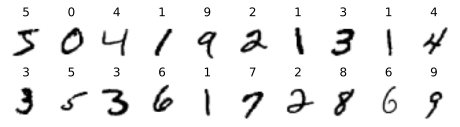

In [4]:
#| label: fig-digits-examples
#| fig-cap: "The first twenty training images of MNIST, each with the digit it is labeled as."
fig, axes = plt.subplots(2, 10, figsize=(8, 2))
for ax, image, label in zip(axes.flat, images_train, y_train):
    ax.imshow(image, cmap="gray_r")
    ax.set_title(label)
    ax.axis("off")
plt.show()

To a network, an image is just a list of numbers. The 28 rows of 28 pixels are laid end to end, which gives 784 numbers, and each number goes to its own input node. Where the tiny network in @sec-nn-tiny had one input, this one has 784.

## Ten answers {#sec-digits-output}

The network must say which of ten digits it sees, so it has ten output neurons, one for each digit. Each produces a score, and the scores are turned into probabilities by a function called *softmax*. It raises $e$ to the power of each score, which makes every number positive and makes high scores much higher, and then divides each result by their total so they add up to 1:

$$
p_i = \frac{e^{s_i}}{e^{s_1} + e^{s_2} + \dots + e^{s_{10}}}
$$

where $s_i$ is the score of output neuron $i$ and $p_i$ is the probability the network gives to digit $i$. With only two outputs, softmax is the sigmoid from @sec-nn-sigmoid in disguise. The network's answer is the digit with the highest probability.

With probabilities as output, the squared error from @sec-train-loss is replaced by a loss that suits them better. For each training image, the loss is minus the logarithm of the probability the network gave to the right digit. If the network is certain of the right answer, that probability is 1 and the loss is 0. The less probability it gives the right answer, the larger the loss, and the slopes of the loss push every weight in the direction that gives the right digit more probability. This loss is called the *cross-entropy*. Everything else about training works as in the last chapter.

## A network without a hidden layer {#sec-digits-linear}

The simplest network for the job has no hidden layer at all. Each of the ten output neurons is connected directly to all 784 pixels, so it has 784 weights and a threshold, and the network has 7,850 parameters in all. scikit-learn calls this *logistic regression*, a name it got in statistics long before anyone thought of it as a network. Creating and training it takes two lines of code, and afterward it reads this share of the test digits correctly:

In [5]:
linear = LogisticRegression(C=0.01, max_iter=200)   # C=0.01 keeps the weights small and smooth
linear.fit(X_train, y_train)
print(f"Correct on the test images: {linear.score(X_test, y_test):.1%}")

Correct on the test images: 91.9%


Since every output neuron has one weight per pixel, we can draw its weights as an image, with each weight placed where its pixel is (@fig-digits-templates). Red means that ink in that pixel raises the neuron's score, and blue means that ink there lowers it. The ten images are templates. The neuron for 0 wants ink in a ring and none in the middle, and the neuron for 1 wants ink in a vertical stripe down the center and none on either side of it. The network reads a digit by comparing it with all ten templates and picking the one it matches best. We asked scikit-learn to keep the weights small during training, which makes the templates smoother and easier to read at the cost of less than a percentage point of accuracy.

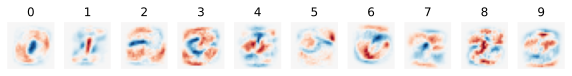

In [6]:
#| label: fig-digits-templates
#| fig-cap: "The weights of the ten output neurons of the network without a hidden layer, each drawn as a 28 by 28 image. Red pixels are positive weights, where ink counts toward that digit, and blue pixels are negative weights, where ink counts against it."
def show_weights(weights, columns, size=28, titles=None, width=10):
    rows = len(weights) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(width, width / columns * rows * 1.1))
    for i, ax in enumerate(np.ravel(axes)):
        limit = abs(weights[i]).max()
        ax.imshow(weights[i].reshape(size, size), cmap="RdBu_r", vmin=-limit, vmax=limit)
        if titles is not None:
            ax.set_title(titles[i])
        ax.axis("off")
    plt.show()

show_weights(linear.coef_, columns=10, titles=range(10))

Template matching works for most digits, but not for all of them. @fig-digits-confusion counts the mistakes on the test images. The most common are twos read as eights, fours and sevens read as nines, nines read as fours, and fives read as threes. These are digits that share most of their strokes, so the ink of one matches the template of the other almost as well as its own. Whether a digit is a 4 or a 9 can depend on a small detail in one place, such as whether the top is closed, and a template that adds up all the ink cannot single out such a detail.

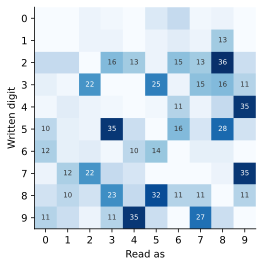

In [7]:
#| label: fig-digits-confusion
#| fig-cap: "The mistakes the network without a hidden layer makes on the 10,000 test images. Each row is the digit that was written and each column the digit it was read as, so the cell in row 4 and column 9 counts the fours read as nines. The correct answers on the diagonal are left out, and the number is shown in every cell with at least ten mistakes."
mistakes = confusion_matrix(y_test, linear.predict(X_test))
np.fill_diagonal(mistakes, 0)                  # leave out the images it got right

fig, ax = plt.subplots(figsize=(4.5, 4))
ax.imshow(mistakes, cmap="Blues")
for true in range(10):
    for guess in range(10):
        if mistakes[true, guess] >= 10:
            color = "white" if mistakes[true, guess] > mistakes.max() / 2 else "#333333"
            ax.text(guess, true, mistakes[true, guess], ha="center", va="center", fontsize=7, color=color)
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("Read as")
ax.set_ylabel("Written digit")
plt.show()

## Adding a hidden layer {#sec-digits-hidden}

Now give the network a hidden layer of 128 neurons between the pixels and the outputs. Each hidden neuron has a weight for each of the 784 pixels and a threshold, and uses the ReLU activation function. The ten output neurons now take their inputs from the hidden neurons instead of from the pixels. That makes 101,770 parameters, about thirteen times as many as before. In scikit-learn this kind of network is called a *multi-layer perceptron*, and again it takes a couple of lines to create and train. scikit-learn trains it in batches of 200 images, as described in @sec-train-practice, with a refined version of gradient descent that adjusts the size of the step for each weight as it goes. @fig-digits-training follows how many of the test digits the network reads correctly after each epoch, that is, after each pass through all 60,000 training images.

101,770 parameters
Correct on the test images: 97.8%


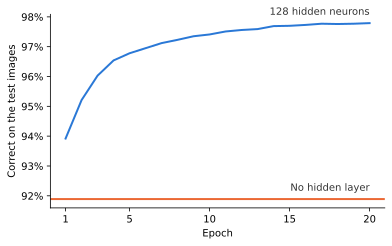

In [8]:
#| label: fig-digits-training
#| fig-cap: "The share of the 10,000 test images read correctly by the network with 128 hidden neurons after each epoch of training (blue), compared with the network without a hidden layer (orange)."
hidden = MLPClassifier(hidden_layer_sizes=(128,), alpha=0.1, random_state=0)   # alpha=0.1 keeps the weights small

accuracy = []
for epoch in range(20):
    hidden.partial_fit(X_train, y_train, classes=range(10))   # one pass through the training images
    accuracy.append(hidden.score(X_test, y_test))

n_parameters = sum(w.size for w in hidden.coefs_) + sum(b.size for b in hidden.intercepts_)
print(f"{n_parameters:,} parameters")
print(f"Correct on the test images: {accuracy[-1]:.1%}")

fig, ax = plt.subplots(figsize=(6, 3.5))
epochs = range(1, 21)
ax.plot(epochs, accuracy, color="#2a78d6", linewidth=2)
ax.axhline(linear.score(X_test, y_test), color="#eb6834", linewidth=2)
ax.text(20, accuracy[-1] + 0.002, "128 hidden neurons", ha="right", va="bottom", color="#333333")
ax.text(20, linear.score(X_test, y_test) + 0.002, "No hidden layer", ha="right", va="bottom", color="#333333")
ax.set_xlabel("Epoch")
ax.set_ylabel("Correct on the test images")
ax.set_xticks([1, 5, 10, 15, 20])
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
plt.show()

The network with a hidden layer beats the one without already after the first epoch. Most of the gain comes in the first five epochs. All twenty take less than half a minute on a laptop, and at the end the network reads 97.8% of the test digits correctly. Its mistakes drop from 811 to 221, so the hidden layer removes almost three out of four of them. @fig-digits-fixed shows some of the digits it now gets right. A few are of the confusable kinds from @fig-digits-confusion, such as a 9 read as a 4 and a 7 read as a 9, and many are just written in a way that no single template matches well.

Mistakes without a hidden layer: 811
Mistakes with a hidden layer:    221


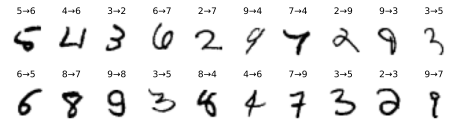

In [9]:
#| label: fig-digits-fixed
#| fig-cap: "Test digits that the network without a hidden layer reads wrong and the network with a hidden layer reads right. Above each image is the digit that was written and, after the arrow, what the network without a hidden layer read it as."
guess_linear = linear.predict(X_test)
guess_hidden = hidden.predict(X_test)
print("Mistakes without a hidden layer:", (guess_linear != y_test).sum())
print("Mistakes with a hidden layer:   ", (guess_hidden != y_test).sum())

fixed = np.where((guess_linear != y_test) & (guess_hidden == y_test))[0]
fig, axes = plt.subplots(2, 10, figsize=(8, 2.1))
for ax, i in zip(axes.flat, fixed):
    ax.imshow(images_test[i], cmap="gray_r")
    ax.set_title(f"{y_test[i]}→{guess_linear[i]}", fontsize=9)
    ax.axis("off")
plt.show()

What do the hidden neurons do? Their weights from the pixels can be drawn as images too, just like the templates (@fig-digits-hidden-weights). They are not digit templates. Most respond to a stroke or a curve in a particular place, with red where ink should be and blue where it should not. Each hidden neuron has become a detector for some feature of the image, and nobody told it which. It ended up that way because that made the loss smaller. One of the 32 neurons shown has all its weights at zero. It is a dead neuron (@sec-nn-relu): it is silent for every training image, so it never got a slope and never learned anything.

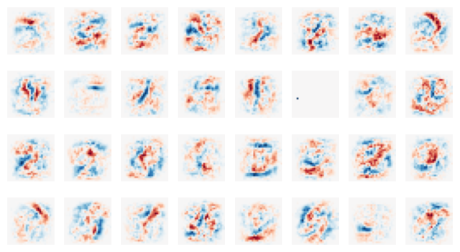

In [10]:
#| label: fig-digits-hidden-weights
#| fig-cap: "The weights from the pixels into the first 32 of the 128 hidden neurons, drawn as images in the same way as @fig-digits-templates."
show_weights(hidden.coefs_[0].T[:32], columns=8, width=8)

The output neurons then decide from the combination of features. @fig-digits-activation shows how strongly each hidden neuron responds, on average, to each digit. Every neuron responds most to one digit, and the neurons are sorted by that digit, which gives the dark blocks along the diagonal. But most neurons also respond to other digits, sometimes almost as strongly. A hidden neuron is not a detector for one digit. It detects a feature that several digits share, and it is the combination of the features that are present and absent that tells the output layer which digit it is looking at. A feature such as a closed loop at the top can count toward 9 and against 4, which is a rule no single template can express.

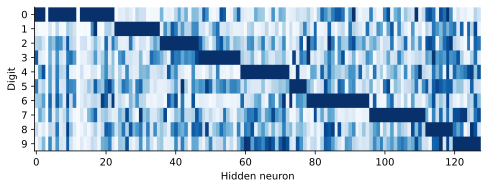

In [11]:
#| label: fig-digits-activation
#| fig-cap: "The average output of each of the 128 hidden neurons (columns) for the test images of each digit (rows). Each column is scaled so that the digit the neuron responds to most is darkest, and the columns are sorted by that digit."
# What the hidden neurons output (ReLU of the net input) for every test image
h = np.maximum(0, X_test @ hidden.coefs_[0] + hidden.intercepts_[0])
average = np.array([h[y_test == digit].mean(axis=0) for digit in range(10)])
average = average / (average.max(axis=0) + 1e-9)      # each neuron's strongest digit gets 1
average = average[:, np.argsort(average.argmax(axis=0), kind="stable")]   # group neurons by that digit

fig, ax = plt.subplots(figsize=(8, 2.6))
ax.imshow(average, aspect="auto", cmap="Blues")
ax.set_yticks(range(10))
ax.set_ylabel("Digit")
ax.set_xlabel("Hidden neuron")
plt.show()

## When templates stop working {#sec-digits-shifted}

The network without a hidden layer does well on MNIST for a reason that has little to do with being clever: the digits are centered. Every image was cropped and positioned so that the digit sits in the middle of the frame, and that is what lets a template expect ink in particular pixels. To see what happens when this is not so, we place each digit at a random position in a larger frame of 36 by 36 pixels, so that it can move up to eight pixels both sideways and up and down (@fig-digits-shifted). For a person, reading these digits is no harder.

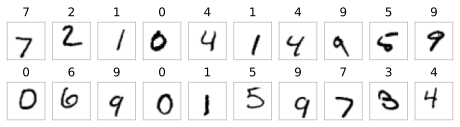

In [12]:
#| label: fig-digits-shifted
#| fig-cap: "The first twenty test images, each placed at a random position in a frame of 36 by 36 pixels. The gray square is the edge of the frame."
def shift(images, seed):
    "Paste each 28 x 28 image at a random place in a 36 x 36 frame."
    rng = np.random.default_rng(seed)
    framed = np.zeros((len(images), 36, 36))
    for i, image in enumerate(images):
        row, column = rng.integers(0, 9, size=2)
        framed[i, row:row + 28, column:column + 28] = image
    return framed

shifted_train = shift(images_train, seed=1)
shifted_test = shift(images_test, seed=2)
Xs_train = shifted_train.reshape(60000, 36 * 36)
Xs_test = shifted_test.reshape(10000, 36 * 36)

fig, axes = plt.subplots(2, 10, figsize=(8, 2))
for ax, image, label in zip(axes.flat, shifted_test, y_test):
    ax.imshow(image, cmap="gray_r")
    ax.set_title(label)
    ax.set_xticks([]); ax.set_yticks([])
    for side in ax.spines.values():
        side.set_visible(True); side.set_color("#bbbbbb")
plt.show()

We then train both networks again on shifted training images and test them on shifted test images (@fig-digits-accuracy). The network without a hidden layer drops from 91.9% to 56.6%. The network with a hidden layer drops only from 97.8% to 94.6%.

In [ ]:
#| label: fig-digits-accuracy
#| fig-cap: "The share of test images read correctly by the two networks, on the centered digits and on the shifted digits."
linear_s = LogisticRegression(C=0.01, max_iter=200).fit(Xs_train, y_train)
hidden_s = MLPClassifier(hidden_layer_sizes=(128,), alpha=0.1, max_iter=20, random_state=0).fit(Xs_train, y_train)

scores = {"No hidden layer": [linear.score(X_test, y_test), linear_s.score(Xs_test, y_test)],
          "128 hidden neurons": [hidden.score(X_test, y_test), hidden_s.score(Xs_test, y_test)]}
for name, (centered, shifted) in scores.items():
    print(f"{name}: {centered:.1%} centered, {shifted:.1%} shifted")

fig, ax = plt.subplots(figsize=(6, 3.5))
for k, (name, color) in enumerate([("No hidden layer", "#eb6834"), ("128 hidden neurons", "#2a78d6")]):
    x = np.arange(2) + (k - 0.5) * 0.36
    bars = ax.bar(x, scores[name], width=0.34, color=color, label=name)
    for bar in bars:
        ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.01,
                f"{bar.get_height():.0%}", ha="center", va="bottom", color="#333333")
ax.set_xticks([0, 1], ["Centered digits", "Shifted digits"])
ax.set_ylim(0, 1.1)
ax.set_yticks([0, 0.25, 0.5, 0.75, 1])
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1, decimals=0))
ax.set_ylabel("Correct on the test images")
ax.legend(frameon=False, loc="upper center", ncols=2, bbox_to_anchor=(0.5, 1.12))
plt.show()

The templates in @fig-digits-blurred show why. A template can only expect ink in fixed pixels, and a 1 written eight pixels to the left puts its ink in completely different pixels from a 1 written eight pixels to the right. The best a template can do is to spread itself over all the places where the digit might be, and the result is a blur that matches many digits about equally badly.

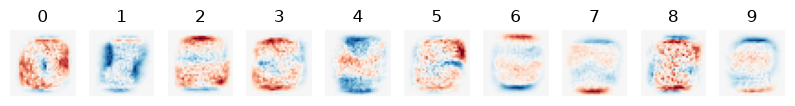

In [ ]:
#| label: fig-digits-blurred
#| fig-cap: "The weights of the ten output neurons of the network without a hidden layer, trained on shifted digits. Compare with @fig-digits-templates."
show_weights(linear_s.coef_, columns=10, size=36, titles=range(10))

The hidden layer has no such problem. @fig-digits-shifted-hidden shows what its neurons became. Many are short strokes and edges, and similar strokes appear in several neurons at different positions. The output layer can then combine the detectors for the same stroke in different places, so that the stroke counts wherever in the frame it is. Networks used for images in practice build this idea into their structure. They slide the same small feature detector across every position of the image, so that a stroke learned in one place is recognized everywhere ([LeCun et al., 1998](https://doi.org/10.1109/5.726791)).

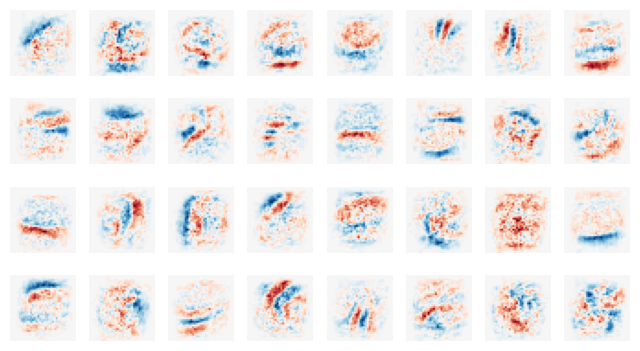

In [ ]:
#| label: fig-digits-shifted-hidden
#| fig-cap: "The weights from the pixels into the first 32 hidden neurons of the network with a hidden layer, trained on shifted digits."
show_weights(hidden_s.coefs_[0].T[:32], columns=8, size=36, width=8)

## The same ideas, scaled up {#sec-digits-scale}

Nothing in this chapter is new compared with the tiny network. Each neuron weights its inputs, subtracts a threshold and applies ReLU, the output is compared with the target by a loss, and backpropagation and gradient descent change every parameter a little in the direction that lowers the loss. There are just more of everything: 784 inputs instead of one, 128 hidden neurons instead of two or three, and 60,000 training examples instead of one. Nobody chose any of the 101,770 parameters, and nobody told the hidden neurons to look for strokes. The network found that this was the way to get the loss down. The next chapter takes the same step once more, from a hundred thousand parameters to hundreds of billions, and from digits to text.

#### Exercise

[AI: Explainer](../intro/course-introduction.qmd#sec-badge-explainer){.small}

Unfold the code under @fig-digits-training and copy only its first line, the one that creates the network, into a fresh conversation with the assistant. Ask it what network the line creates: how many layers it has, how many neurons there are in each, which activation function the hidden neurons use, and how many parameters the network has in total. Then settle each claim in its answer yourself. The scikit-learn documentation for [MLPClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.neural_network.MLPClassifier.html) says which activation function is used when none is given, and you can count the parameters by hand from the number of weights and thresholds in each layer and compare your count with the number printed above the figure.

::: {.callout-tip collapse="true" appearance="minimal" icon=false}

## What does the line actually say?

It says only that there is one hidden layer with 128 neurons. The number of inputs and outputs is not in it: scikit-learn takes them from the data when the network is trained, 784 inputs for the pixels and 10 outputs for the digits. If the assistant stated them as if the line said so, it filled the gap with what such networks usually look like, which happens to be right here but is not something it could know from the line. The documentation gives `'relu'` as the default activation function. The parameters are $784 \times 128$ weights and 128 thresholds into the hidden layer, and $128 \times 10$ weights and 10 thresholds into the output layer, which makes 101,770.
:::